# machine learning and wave predictions---figures

In [1]:
%load_ext autoreload
%autoreload 2
#this is to avoid to restart the kernel everytime we change our helper functions e.g. utils ...

## helper functions
- Importing all required packages
- tf '2.6.2' version was first used...

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_squared_error, r2_score

from windrose import WindroseAxes
from matplotlib import cm
from matplotlib.offsetbox import AnchoredText
import geocat.viz as gv # for taylor diagram
import shapely.geometry as sgeom
import matplotlib.colors as mcolors

import utils #salika scripts...
import storm_detection
from modified_taylor import TaylorDiagram

#for maps
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import matplotlib.patches as patches
from matplotlib.colors import LogNorm, LinearSegmentedColormap, ListedColormap

### common definitions, package things...

In [3]:
n_jobs = 1  #leads to use the gpu?
random_state = 42 #this is my preference, some people like to use 42...
hereon_cp = utils.hereon_cp
#call for figures pre-defined style...
utils.scientific_graphs()
# Ensure reproducibility by setting the random state...
np.random.seed(random_state)

## figures for the manuscript

In [4]:
#import predicted data from pytorch, compare with data assimilation from WAM--this is from the run of 25.03.2026
test_wam_df = pd.read_parquet("../results/2026_06_29_wave_data_wam_SEE.parquet", engine="auto")
test_pyt_df  = pd.read_parquet("../results/2026_06_29_wave_data_pyt_SEE.parquet", engine="auto")

In [7]:
def eval_extremes(obs_df, pred_df, feature, pct=95):
    mask = obs_df[feature] >= obs_df[feature].quantile(pct / 100)

    obs = obs_df.loc[mask, feature]
    pred = pred_df.loc[obs.index, feature]

    r = obs.corr(pred)
    r2 = r2_score(obs, pred)
    bias = (pred - obs).mean()
    mae = mean_absolute_error(obs, pred)

    return pd.Series(
        {"N": len(obs), "R": r, "R2": r2, "Bias": bias, "MAE": mae}
    )

In [11]:
eval_extremes(test_wam_df,test_pyt_df, 'hs',0)

N       140256.000000
R            0.976933
R2           0.950114
Bias         0.032658
MAE          0.137751
dtype: float64

In [9]:
eval_extremes(test_wam_df,test_pyt_df, 'hs',98)

N       2806.000000
R          0.905052
R2         0.783400
Bias       0.054089
MAE        0.331761
dtype: float64

In [10]:
eval_extremes(test_wam_df,test_pyt_df, 'hs',99)

N       1403.000000
R          0.864621
R2         0.671818
Bias       0.040362
MAE        0.382120
dtype: float64

np.float64(2.737292766571045)

### storm identification

In [5]:
utils.hereon_cp

[(0.0, 0.5686274509803921, 0.6274509803921569),
 (0.9019607843137255, 0.0, 0.27450980392156865),
 (0.0, 0.6666666666666666, 0.9019607843137255),
 (0.9803921568627451, 0.45098039215686275, 0.3137254901960784),
 (0.9803921568627451, 0.7058823529411765, 0.13725490196078433),
 (0.5490196078431373, 0.35294117647058826, 0.7058823529411765),
 (0.34901960784313724, 0.34901960784313724, 0.34901960784313724),
 (0.7725490196078432, 1.0, 0.9921568627450981),
 (0.5333333333333333, 0.8509803921568627, 0.9019607843137255)]

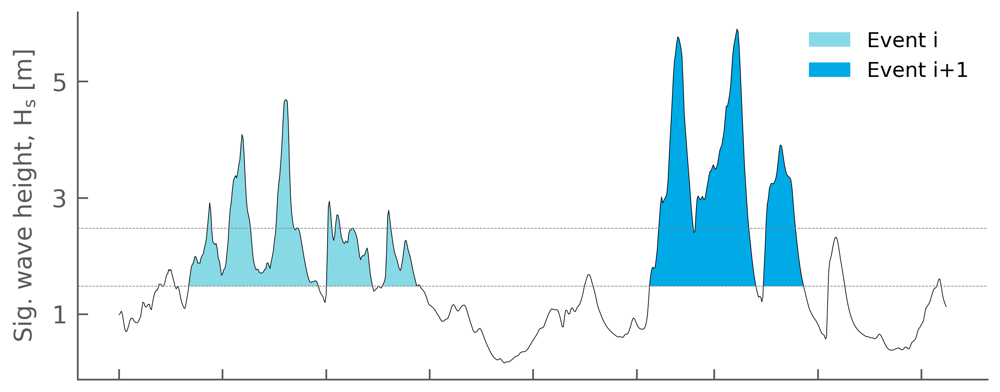

In [6]:
date_range = ('2023-01-09', '2023-02-09')
data = test_wam_df.loc[date_range[0]:date_range[1], 'hs']

fig, axs = plt.subplots(1, 1, figsize=(4.2, 1.75), dpi=600)
# Plot the wave height
axs.plot(data.index, data.values, lw=0.2, color='k')
# Highlight specific date ranges
axs.fill_between(
    data.index, 1.48, data.values,
    where=(data.index >= '2023-01-11 17:00:00') & (data.index <= '2023-01-20 11:00:00') & (data.values > 1.5),
    color=utils.hereon_cp[8], alpha=1, edgecolor='none', interpolate=True
)
axs.fill_between(
    data.index, 1.48, data.values,
    where=(data.index >= '2023-01-29 12:00:00') & (data.index <= '2023-02-04 10:00:00') & (data.values > 1.5),
    color=utils.hereon_cp[2], alpha=1, edgecolor='none', interpolate=True
)

# Threshold lines
axs.axhline(1.48, lw=0.2, color='gray', linestyle='--')
axs.axhline(2.48, lw=0.2, color='gray', linestyle='--')

# Customize axes
axs.spines['top'].set_visible(False)
axs.spines['right'].set_visible(False)
axs.yaxis.tick_left()
axs.xaxis.tick_bottom()
axs.tick_params(which='minor', bottom=False, left=False)

axs.set_xticklabels([])

axs.set_ylabel('Sig. wave height, H$_s$ [m]')

# Set y-axis ticks explicitly
axs.set_yticks([1, 3, 5])  # <--- Add this line

# Create custom legend handles
legend_elements = [
    Patch(facecolor=utils.hereon_cp[8], label='Event i'),
    Patch(facecolor=utils.hereon_cp[2], label='Event i+1')
]

# Add legend with custom handles
axs.legend(handles=legend_elements, 
          loc='upper right', 
          fontsize=6, 
          frameon=False)

# Save and display the figure
fig.tight_layout()
# fig.savefig(f'../results/figures/storm-def.png', dpi=600)

### perforamnces

In [7]:
features = ['hs', 't0','thq'] #
for i, predictand in enumerate(features):
    print(
        f'performance for {predictand}: \nR^2 {r2_score(test_wam_df[predictand],test_pyt_df[predictand])}\nr {pearsonr(test_wam_df[predictand],test_pyt_df[predictand])[0]}'
    )

performance for hs: 
R^2 0.9501141309738159
r 0.9769327640533447
performance for t0: 
R^2 0.8002188801765442
r 0.8979020118713379
performance for thq: 
R^2 0.7907061576843262
r 0.8923031091690063


In [8]:
# Convert to radians
wam_rad = np.deg2rad(test_wam_df["thq"].to_numpy())
pyt_rad = np.deg2rad(test_pyt_df["thq"].to_numpy())

In [9]:
pyt_rad.min(),pyt_rad.max()

(np.float32(0.0003173435), np.float32(6.283121))

In [10]:
wam_rad.min(),wam_rad.max()

(np.float32(0.00024181501), np.float32(6.2831407))

In [11]:
np.degrees(pyt_rad)

array([177.60802 , 176.4562  , 175.49382 , ...,  31.8236  ,  38.62164 ,
        41.300953], shape=(140256,), dtype=float32)

In [12]:
test_wam_df.loc[:,'hs'].values.min(),test_wam_df.loc[:,'hs'].values.max()

(np.float32(0.045564972), np.float32(8.268929))

In [13]:
(np.float64(0.045564972),
 np.float64(0.595793425),
 np.float64(0.95410108),
 np.float64(1.4744587),
 np.float64(8.268929))

(np.float64(0.045564972),
 np.float64(0.595793425),
 np.float64(0.95410108),
 np.float64(1.4744587),
 np.float64(8.268929))

In [14]:
[0,0.60,0.95,1.47]

[0, 0.6, 0.95, 1.47]

In [15]:
ce_wavedir_cmap = ListedColormap(["#D9E2B6", "#E5CA8A", "#DFA55F", "#C63732"], name="ce_wavedir_cmap")

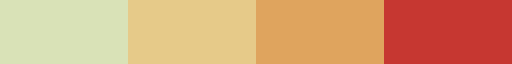

In [16]:
ce_wavedir_cmap

- more reading on how to edit the windrose: 
https://python-windrose.github.io/windrose/

In [17]:
wam_rad

array([2.8139756 , 2.8154202 , 2.815544  , ..., 0.47051916, 0.63091093,
       0.7111895 ], shape=(140256,), dtype=float32)

/sw/spack-levante/miniforge3-24.11.3-2-Linux-x86_64-hbhytx/lib/python3.12/site-packages/IPython/core/events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
/sw/spack-levante/miniforge3-24.11.3-2-Linux-x86_64-hbhytx/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


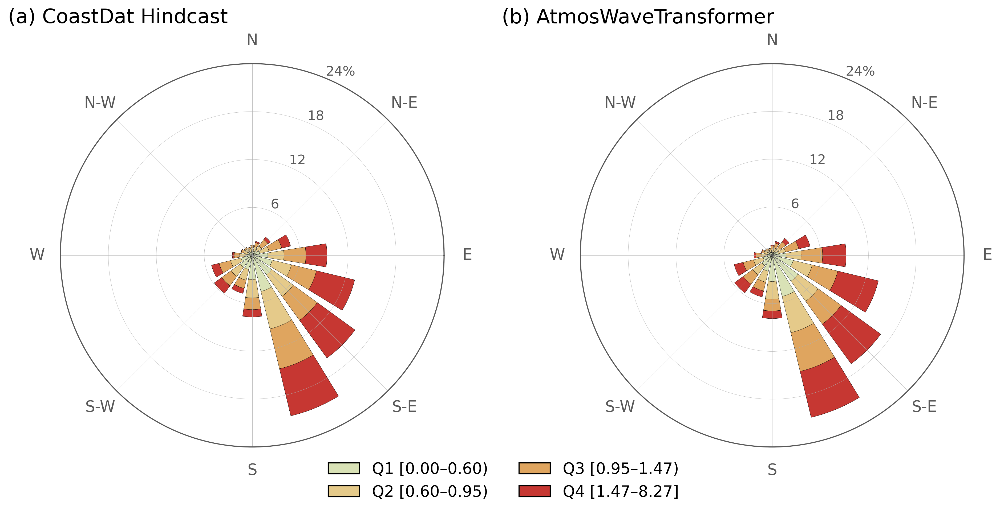

In [18]:
# data for wind-roses
pyt_hs = test_pyt_df.loc[:,'hs'].values
wam_hs = test_wam_df.loc[:,'hs'].values

# Create figure with two wind roses
fig = plt.figure(figsize=(6.505, 3), dpi=600)

# Windrose for wam model
ax1 = WindroseAxes.from_ax(fig=fig, rect=[0.05, 0.1, 0.4, 0.8])
ax1.bar(
    np.degrees(wam_rad), wam_hs, normed=True, opening=0.8, 
    linewidth=0.1, edgecolor='k', bins=[0,0.60,0.95,1.47], cmap=ce_wavedir_cmap
)
ax1.text(np.radians(120), 24*1.4, '(a) CoastDat Hindcast', ha='center')
ax1.set_rmax(24)
ax1.set_rgrids([6, 12, 18, 24], labels=['6', '12', '18', '24%'], fontsize=6, color = utils.hereon_cp[6])
for line in ax1.yaxis.get_gridlines():
    line.set_linewidth(0.1)
for line in ax1.xaxis.get_gridlines():
    line.set_linewidth(0.1)

# ax1.set_title('(a) coastDat')

# Windrose for pytorch
ax2 = WindroseAxes.from_ax(fig=fig, rect=[0.55, 0.1, 0.4, 0.8])
ax2.bar(
    np.degrees(pyt_rad), pyt_hs, normed=True, opening=0.8, calm_limit=0,
    linewidth=0.1, edgecolor='k', bins=[0,0.60,0.95,1.47], cmap=ce_wavedir_cmap  #np.arange(0, 8, 2) , cm.hot
)
ax2.text(np.radians(120), 24*1.4, '(b) AtmosWaveTransformer', ha='center')
ax2.set_rmax(24)
ax2.set_rgrids([6, 12, 18, 24], labels=['6', '12', '18', '24%'], fontsize=6, color = utils.hereon_cp[6])
for line in ax2.yaxis.get_gridlines():
    line.set_linewidth(0.1)
for line in ax2.xaxis.get_gridlines():
    line.set_linewidth(0.1)
# ax2.set_title('(b) PyTorch model')

leg = ax2.set_legend(loc='lower center', bbox_to_anchor=(-0.2, -0.15), ncol=2,  fontsize=7, frameon=False)

# new labels matching your bins
new_labels = [
    "Q1 [0.00–0.60)",
    "Q2 [0.60–0.95)",
    "Q3 [0.95–1.47)",
    "Q4 [1.47–8.27]"
]

for txt, label in zip(leg.get_texts(), new_labels):
    txt.set_text(label)
    txt.set_fontsize(7)

for patch in leg.get_patches():
    patch.set_linewidth(0.5)   # adjust thickness
    patch.set_edgecolor('black')

# fig.savefig(f'../results/figures/fig_wave_dir_windrose.png', dpi=600)

### Q-Q PLOTS

In [19]:
hereon_cp

[(0.0, 0.5686274509803921, 0.6274509803921569),
 (0.9019607843137255, 0.0, 0.27450980392156865),
 (0.0, 0.6666666666666666, 0.9019607843137255),
 (0.9803921568627451, 0.45098039215686275, 0.3137254901960784),
 (0.9803921568627451, 0.7058823529411765, 0.13725490196078433),
 (0.5490196078431373, 0.35294117647058826, 0.7058823529411765),
 (0.34901960784313724, 0.34901960784313724, 0.34901960784313724),
 (0.7725490196078432, 1.0, 0.9921568627450981),
 (0.5333333333333333, 0.8509803921568627, 0.9019607843137255)]

### t-diagrams

**notes**
- https://geocat-viz.readthedocs.io/en/latest/examples/taylor.html
- https://geocat-examples.readthedocs.io/en/latest/gallery/TaylorDiagrams/NCL_taylor_2.html

#### data preparation

##### quartiles based on Nik's suggestion. 23.03.2026

In [20]:
q1, q2, q3 = test_wam_df['hs'].quantile(.25), test_wam_df['hs'].quantile(.5), test_wam_df['hs'].quantile(.75)

In [21]:
#from hindcast hs values in the test dataset
q1, q2, q3

(np.float64(0.5962876528501511),
 np.float64(0.9564903974533081),
 np.float64(1.47923144698143))

##### old way---hs and tm02 quartiles are calculated using their own.

In [22]:
hs_stats_by_q =  utils.compute_quantile_stats(test_wam_df['hs'],test_pyt_df['hs'], 4)
t0_stats_by_q =  utils.compute_quantile_stats(test_wam_df['t0'],test_pyt_df['t0'], 4)

/work/gg0303/g260244/metascales/wave-forecasts/codes/utils.py:122: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stats_by_q = df.groupby("obs_q").apply(
/work/gg0303/g260244/metascales/wave-forecasts/codes/utils.py:122: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stats_by_q = df.groupby("obs_q").apply(


In [23]:
# taystat for set hs
hs_sdev  = hs_stats_by_q.std_pred/hs_stats_by_q.std_obs   # standard deviations (normalized by dividing the obs std)
hs_ccorr = hs_stats_by_q.spearman_corr # correlations
hs_bias  = 100*hs_stats_by_q.bias_mean        # bias (%)

# taystat for set t0
t0_sdev  = t0_stats_by_q.std_pred/t0_stats_by_q.std_obs   # standard deviations (normalized by dividing the obs std)
t0_ccorr = t0_stats_by_q.spearman_corr # correlations
t0_bias  = 100*t0_stats_by_q.bias_mean        # bias (%)

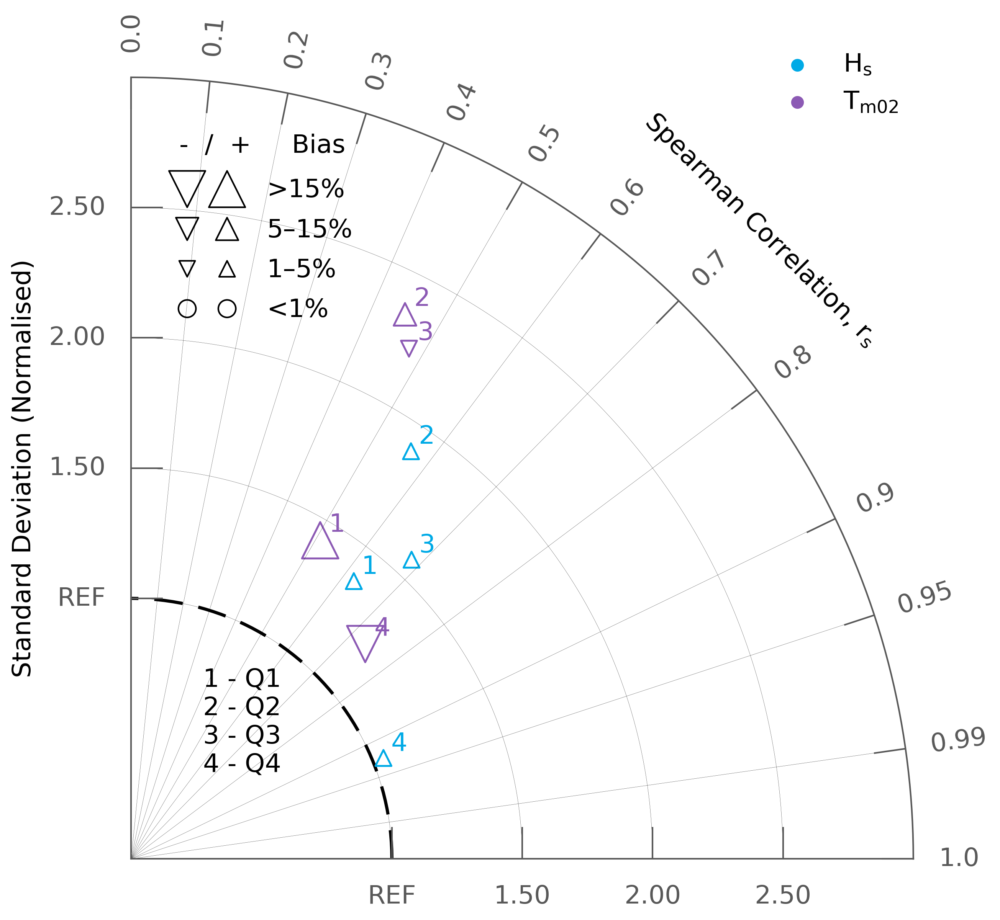

In [24]:
var_list = [f"Q{i}" for i in range(1, len(hs_bias) + 1)]

# ---- CREATE TAYLOR DIAGRAM ----
fig = plt.figure(figsize=(4.2, 4.2), dpi=600)

taylor = TaylorDiagram(
    fig=fig,
    std_range=(0, 3),
    std_level=np.array([1., 1.5, 2.0, 2.5]),
)

# ---- MODEL SET: T0 ----
Texts, _ = taylor.add_model_set(
    t0_sdev,
    t0_ccorr,
    model_outlier_on=False,
    percent_bias_on=True,
    bias_array=t0_bias,
    label=r'$T_{m02}$',
    edgecolors=hereon_cp[5],
    facecolors='none',
    linewidths=0.6,   # slightly clearer
    xytext=(23, 23)
)

# ---- MODEL SET: Hs ----
Texts, _ = taylor.add_model_set(
    hs_sdev,
    hs_ccorr,
    model_outlier_on=False,
    percent_bias_on=True,
    bias_array=hs_bias,
    label=r'$H_s$',
    edgecolors=hereon_cp[2],
    facecolors='none',
    linewidths=0.6,
    xytext=(20, 20)
)

# ---- MODEL LABELS ----
taylor.add_model_name(
    var_list,
    x_loc=0.1,
    y_loc=0.25,
    verticalalignment='top'
)

# ---- BIAS LEGEND (clean control now) ----
taylor.add_bias_legend()

# ---- MAIN LEGEND ----
leg = taylor.add_legend(fontsize=8)
leg.set_bbox_to_anchor((1.0, 1.05))  # slight lift to avoid overlap

# ---- AXIS LABELS ----
taylor._ax.axis["top"].label.set_text("Spearman Correlation, $r_s$")
taylor._ax.axis["right"].label.set_text("Standard Deviation (Normalised)")

# ---- FONT CONSISTENCY ----
taylor._ax.axis['top', 'right', 'left'].major_ticklabels.set_fontsize(8)
taylor._ax.axis['top', 'right'].label.set_fontsize(8)
taylor._ax.axis['top', 'right'].label.set_pad(4)

taylor.ax.tick_params(labelsize=8)

# Reduce all text sizes consistently
for txt in taylor.ax.texts:
    txt.set_fontsize(8)

# ---- GRID ----
taylor.add_grid(color='k', linewidth=0.05)

# ---- LAYOUT (important: no subplots_adjust anymore) ----
plt.tight_layout(pad=0.5)


# ---- CHANGE TICK LABEL COLORS ----
for axis in ['top', 'right', 'left']:
    taylor._ax.axis[axis].major_ticklabels.set_color(hereon_cp[6])

# ---- CHANGE AXIS LABEL COLORS ----
taylor._ax.axis["top"].label.set_color('k')
taylor._ax.axis["right"].label.set_color('k')


# ---- SAVE ----
# fig.savefig('../results/figures/fig_taylor-diagram.png', dpi=900, bbox_inches='tight')

#### testing performace for a giving time period

In [25]:
f'testing period from: {test_wam_df.index[0]} to {test_wam_df.index[-1]}'

'testing period from: 2008-01-01 00:00:00 to 2023-12-31 23:00:00'

### storm events

In [26]:
# test_wam_df.loc[:, ['hs']].quantile(.75),test_wam_df.loc[:, ['hs']].quantile(.95)

# use the whole dataset values: 1.48 and 7.75

In [12]:
wam_wave_storms = storm_detection.detect_wave_storms(
    test_wam_df.loc[:, ['hs','t0','thq']], 
    freq_hours = 1.0,
    threshold1= 1.48,
    threshold2 = 2.75,
    min_duration= 6,
    min_gap = 48
)

In [13]:
wam_wave_storms['storm_power'] = wam_wave_storms['duration_hours'] * wam_wave_storms['max_hs']**2

In [14]:
idx = (
    wam_wave_storms
    .groupby(wam_wave_storms['time_max_hs'].dt.year)['storm_power']
    .idxmax()
)

In [15]:
wam_wave_storms.loc[idx].sort_values('start_time').loc[:,:]

,start_time,end_time,duration_hours,max_hs,time_max_hs,mean_hs,mean_t0,mean_thq,storm_id,storm_power
5,2008-02-21 13:00:00,2008-03-07 00:00:00,347.0,7.380053,2008-03-01 13:00:00,2.797606,6.004509,132.404205,6,18899.415943
26,2009-09-30 20:00:00,2009-10-05 11:00:00,111.0,5.766103,2009-10-04 05:00:00,2.978107,6.181708,136.043411,27,3690.521347
41,2010-10-18 16:00:00,2010-10-26 05:00:00,181.0,5.044798,2010-10-24 09:00:00,2.624688,5.728148,132.214462,42,4606.447376
60,2011-12-02 08:00:00,2011-12-21 15:00:00,463.0,7.302068,2011-12-09 08:00:00,2.447299,5.727572,133.148849,61,24687.249935
62,2012-01-02 15:00:00,2012-01-09 02:00:00,155.0,6.354467,2012-01-05 16:00:00,3.729437,6.800479,130.278824,63,6258.784866
90,2013-11-28 08:00:00,2013-12-10 00:00:00,280.0,8.268929,2013-12-06 07:00:00,3.072735,6.209279,131.931931,91,19145.049133
102,2014-12-09 19:00:00,2014-12-25 22:00:00,387.0,6.471594,2014-12-20 18:00:00,2.788785,5.803279,126.833946,103,16208.153881
104,2015-01-08 19:00:00,2015-01-18 12:00:00,233.0,6.322485,2015-01-11 14:00:00,3.010238,5.895739,112.889908,105,9313.900887
132,2016-12-22 22:00:00,2016-12-28 08:00:00,130.0,7.662793,2016-12-27 03:00:00,3.242290,6.390260,125.638496,133,7633.390884
134,2017-01-11 00:00:00,2017-01-15 16:00:00,112.0,7.954803,2017-01-13 19:00:00,4.066069,7.587887,139.970886,135,7087.236389


In [16]:
10.545252-9.948362

0.5968900000000001

In [31]:
# wam_wave_storms.loc[(wam_wave_storms['start_time'].dt.year == 2009) & (wam_wave_storms['start_time'].dt.month == 1)]

In [32]:
test_wam_df.thq.max()

np.float32(359.99744)

In [ ]:
eval_extremes(test_wam_df.loc[date1:date2],test_pyt_df, 'hs',0)

<string>:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
<string>:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
<string>:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
<string>:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
<string>:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
<string>:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
<string>:57: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
<string>:57: 

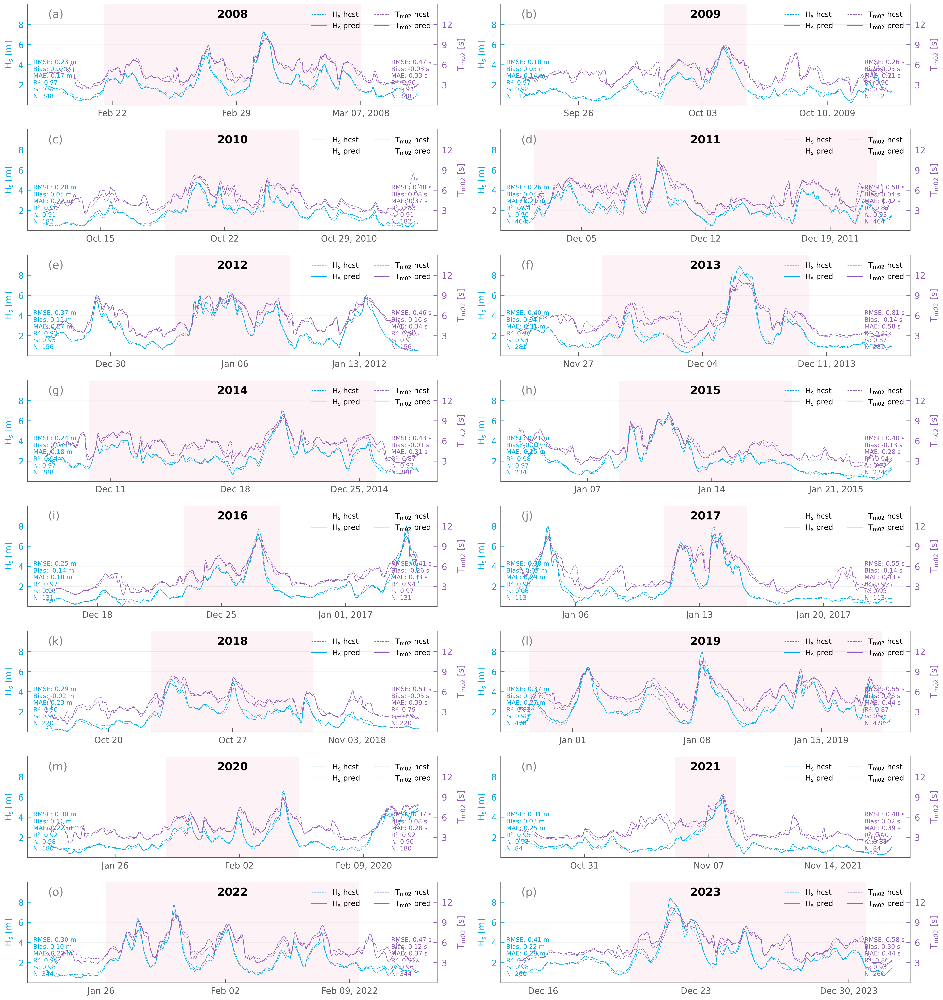

In [27]:
metrics_on=Fal
fig, axes = plt.subplots(8, 2, figsize=(10.8, 11.439), dpi=600)     #7.2 6.5  --10.8, 12 works ...
storm_detection.plot_storm(test_wam_df,test_pyt_df, '2008-02-21 13:00:00','2008-03-07 00:00:00', '2008', metrics_on=metrics_on, ax=axes[0,0], fig_num="(a)")
storm_detection.plot_storm(test_wam_df,test_pyt_df, '2009-09-30 20:00:00','2009-10-05 11:00:00', '2009', metrics_on=metrics_on, ax=axes[0,1], fig_num="(b)")
storm_detection.plot_storm(test_wam_df,test_pyt_df, '2010-10-18 16:00:00','2010-10-26 05:00:00', '2010', metrics_on=metrics_on, ax=axes[1,0], fig_num="(c)")
storm_detection.plot_storm(test_wam_df,test_pyt_df, '2011-12-02 08:00:00','2011-12-21 15:00:00', '2011', metrics_on=metrics_on, ax=axes[1,1], fig_num="(d)")
storm_detection.plot_storm(test_wam_df,test_pyt_df, '2012-01-02 15:00:00','2012-01-09 02:00:00', '2012', metrics_on=metrics_on, ax=axes[2,0], fig_num="(e)")
storm_detection.plot_storm(test_wam_df,test_pyt_df, '2013-11-28 08:00:00','2013-12-10 00:00:00', '2013', metrics_on=metrics_on, ax=axes[2,1], fig_num="(f)")
storm_detection.plot_storm(test_wam_df,test_pyt_df, '2014-12-09 19:00:00','2014-12-25 22:00:00', '2014', metrics_on=metrics_on, ax=axes[3,0], fig_num="(g)")
storm_detection.plot_storm(test_wam_df,test_pyt_df, '2015-01-08 19:00:00','2015-01-18 12:00:00', '2015', metrics_on=metrics_on, ax=axes[3,1], fig_num="(h)")
storm_detection.plot_storm(test_wam_df,test_pyt_df, '2016-12-22 22:00:00','2016-12-28 08:00:00', '2016', metrics_on=metrics_on, ax=axes[4,0], fig_num="(i)")
storm_detection.plot_storm(test_wam_df,test_pyt_df, '2017-01-11 00:00:00','2017-01-15 16:00:00', '2017', metrics_on=metrics_on, ax=axes[4,1], fig_num="(j)")
storm_detection.plot_storm(test_wam_df,test_pyt_df, '2018-10-22 10:00:00','2018-10-31 13:00:00', '2018', metrics_on=metrics_on, ax=axes[5,0], fig_num="(k)")
storm_detection.plot_storm(test_wam_df,test_pyt_df, '2018-12-29 13:00:00','2019-01-18 10:00:00', '2019', metrics_on=metrics_on, ax=axes[5,1], fig_num="(l)")
storm_detection.plot_storm(test_wam_df,test_pyt_df, '2020-01-28 21:00:00','2020-02-05 08:00:00', '2020', metrics_on=metrics_on, ax=axes[6,0], fig_num="(m)")
storm_detection.plot_storm(test_wam_df,test_pyt_df, '2021-11-05 02:00:00','2021-11-08 13:00:00', '2021', metrics_on=metrics_on, ax=axes[6,1], fig_num="(n)")
storm_detection.plot_storm(test_wam_df,test_pyt_df, '2022-01-26 06:00:00','2022-02-09 13:00:00', '2022', metrics_on=metrics_on, ax=axes[7,0], fig_num="(o)")
storm_detection.plot_storm(test_wam_df,test_pyt_df, '2023-12-20 00:00:00','2023-12-30 19:00:00', '2023', metrics_on=metrics_on, ax=axes[7,1], fig_num="(p)")
# axes[7,1].set_visible(False)
fig.tight_layout()
fig.savefig(f'../results/figures/fig_wave_storm-predictions.png', dpi=600)
plt.show()

### scatter density plots with Q-Q plots on top of them

In [58]:
ce_hereon_cmap = LinearSegmentedColormap.from_list(
    'ce_hereon_cmap',
    ['#f9bfd1', '#E60046'],  #fef1f5, f9bfd1, FFFFFF  ---#f9bfd1', '#f27fa2', '#ec3f74', '#e60046'
    N=256
)

In [59]:
ce_hereon_colors_5 = [ce_hereon_cmap(i) for i in np.linspace(0, 1, 5)]
ce_hereon_cmap_5 = ListedColormap(ce_hereon_colors_5, name='ce_hereon_cmap_5')

In [60]:
ce_pop_cmap = ListedColormap(["#C7E5DF", "#D9E2B6", "#E5CA8A", "#DFA55F", "#C63732"], name="ce_pop_cmap")

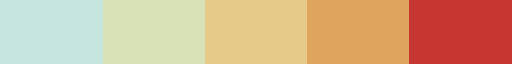

In [61]:
ce_pop_cmap

In [62]:
# ce_hereon_cmap = [ce_hereon_cmap(i) for i in np.linspace(0, 1, 5)]

In [63]:
def compute_logspaced_quantiles(hs_obs, hs_pred, t0_obs, t0_pred, n=100, eps=1e-3):
    """
    Compute upper-tail log-spaced quantiles for Hs and T0
    for prediction (pyt_df) and observation (wam_df) data.
    """

    # Log‑spaced quantile levels (dense near 1)
    q = 1 - np.logspace(np.log10(eps), 0, n)
    # q = q[(q > eps) & (q < 1 - eps)]  # trim if needed
    
    # Compute quantiles
    hs_obs_q  = np.quantile(hs_obs,  q)
    hs_pred_q = np.quantile(hs_pred, q)
    t0_obs_q  = np.quantile(t0_obs,  q)
    t0_pred_q = np.quantile(t0_pred, q)

    return hs_obs_q, hs_pred_q, t0_obs_q, t0_pred_q

In [64]:
def plot_density_scatter(hs_obs, hs_pred, t0_obs, t0_pred,figsize=(4.8, 2.2), dpi=600):

    #valules for the Q-Q plot:
    hs_obs_q, hs_pred_q, t0_obs_q, t0_pred_q = compute_logspaced_quantiles(hs_obs, hs_pred, t0_obs, t0_pred, n=25, eps=1e-3)
    
    fig, axes = plt.subplots(1, 2, figsize=figsize, dpi=dpi, sharex=False, sharey=False)

    # ---- Hs: obs vs pred ----
    hb1 = axes[0].hexbin(
        hs_obs, hs_pred,
        gridsize=25,
        cmap=ce_pop_cmap,
        norm=LogNorm(),   # comment out if you prefer linear scale
        mincnt=0
    )
    axes[0].plot([hs_obs.min(), hs_obs.max()],
                 [hs_obs.min(), hs_obs.max()],
                 color=hereon_cp[1], lw=0.5)
    axes[0].plot(hs_obs_q, hs_pred_q, 'o', ##### Q--Q plot for hs
         markersize=3, markerfacecolor=hereon_cp[2],
         markeredgecolor='none', markeredgewidth=0.2)
    # percentiles for Hs
    p_levels = [50, 90, 99]
    hs_obs_3p = np.percentile(hs_obs, p_levels)  
    hs_pred_3p = np.percentile(hs_pred, p_levels)   
    # plot red dots
    axes[0].plot(hs_obs_3p, hs_pred_3p, 'o',
             markerfacecolor='none',markeredgecolor='white',
             markeredgewidth=0.8,markersize=3,zorder=5)

    axes[0].set_xlabel('CoastDat Hindcast H$_s$ [m]', color = 'k')
    axes[0].set_ylabel('AtmosWaveTransformer H$_s$ [m]', color = 'k')
    # axes[0].set_ylim(-2.9,2.9)
    axes[0].grid(linewidth = 0.05)
    axes[0].text(0.075, 0.95, '(a)', ha='left', va='top', transform=axes[0].transAxes, color = hereon_cp[6])
    # Metrics box
    metrics_text = (
        f"RMSE: {root_mean_squared_error(hs_obs, hs_pred):.2f} m\n" #root_mean_squared_error, f"MSE: {mean_squared_error(y_true, y_pred):.2f}\n"
        f"Bias: {np.mean(hs_pred - hs_obs):.2f} m\n"  #bias = np.mean(t0_pred - t0_obs)
        f"MAE: {mean_absolute_error(hs_obs, hs_pred):.2f} m\n"
        f"R²: {r2_score(hs_obs, hs_pred):.2f}\n"
        f"rₛ: {spearmanr(hs_obs, hs_pred)[0]:.2f}\n"
        f"NObs: {len(hs_obs):,}" 
    )
    at_hs = AnchoredText(metrics_text,
                      loc=4,
                      prop=dict(size=5, color=hereon_cp[6]),
                      frameon=False,
                      bbox_transform=axes[0].transData)
    axes[0].add_artist(at_hs)
    # ---- T0: obs vs pred ----
    hb2 = axes[1].hexbin(
        t0_obs, t0_pred,
        gridsize=25,
        cmap=ce_pop_cmap,  #'tab20b'
        norm=LogNorm(),   # same as above
        mincnt=1
    )
    axes[1].plot([t0_obs.min(), t0_obs.max()],
                 [t0_obs.min(), t0_obs.max()],
                 color=hereon_cp[1], lw=0.5)
    axes[1].plot(t0_obs_q, t0_pred_q, 'o', ##### Q--Q plot for hs
         markersize=3, markerfacecolor=hereon_cp[5],
         markeredgecolor='none', markeredgewidth=0.2)
    # percentiles for Tm02
    t0_obs_3p = np.percentile(t0_obs, p_levels)  
    t0_pred_3p = np.percentile(t0_pred, p_levels)   
    # plot red dots
    axes[1].plot(t0_obs_3p, t0_pred_3p, 'o',
             markerfacecolor='none',markeredgecolor='white',
             markeredgewidth=0.8,markersize=3,zorder=5)
    
    axes[1].set_xlabel('CoastDat Hindcast $T_{m02}$ [s]', color = 'k')
    axes[1].set_ylabel('AtmosWaveTransformer $T_{m02}$ [s]', color = 'k')
    # axes[1].set_ylim(-6.9,6.9)
    axes[1].grid(linewidth = 0.05)
    axes[1].text(0.075, 0.95, '(b)', ha='left', va='top', transform=axes[1].transAxes, color = hereon_cp[6])
    # Metrics box
    metrics_text = (
        f"RMSE: {root_mean_squared_error(t0_obs, t0_pred):.2f} s\n" #root_mean_squared_error, f"MSE: {mean_squared_error(y_true, y_pred):.2f}\n"
        f"Bias: {np.mean(t0_pred - t0_obs):.2f} s\n"  #bias = np.mean(t0_pred - t0_obs)
        f"MAE: {mean_absolute_error(t0_obs, t0_pred):.2f} s\n"
        f"R²: {r2_score(t0_obs, t0_pred):.2f}\n"
        f"rₛ: {spearmanr(t0_obs, t0_pred)[0]:.2f}\n"
        f"NObs: {len(t0_obs):,}"
    )
    at_t0 = AnchoredText(metrics_text,
                      loc=4,
                      prop=dict(size=5, color=hereon_cp[6]),
                      frameon=False,
                      bbox_transform=axes[1].transData)
    axes[1].add_artist(at_t0)
    
    for ax in [axes[0], axes[1]]:
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.yaxis.tick_left()
        ax.xaxis.tick_bottom()

    # ---- Make color scale common to both plots ----
    # Get max density from both hexbin results
    vmax = max(hb1.get_array().max(), hb2.get_array().max())
    vmin = min(hb1.get_array()[hb1.get_array() > 0].min(),
               hb2.get_array()[hb2.get_array() > 0].min()) if isinstance(hb1.norm, LogNorm) else 0

    hb1.set_clim(vmin=vmin, vmax=vmax)
    hb2.set_clim(vmin=vmin, vmax=vmax)

    # ---- One shared colorbar for both ----
     
    fig.tight_layout()  # make sure axes positions are finalized first
    pos = axes[1].get_position()
    cax = fig.add_axes([pos.x1 + 0.02, pos.y0, 0.02, pos.height])
  
    # [left, bottom, width, height] in figure fraction (0–1)
    
    cbar = fig.colorbar(hb1, cax=cax, label='Point density')


    # fig.tight_layout()
    return fig, axes, cbar

/tmp/ipykernel_2179147/3689115666.py:7: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


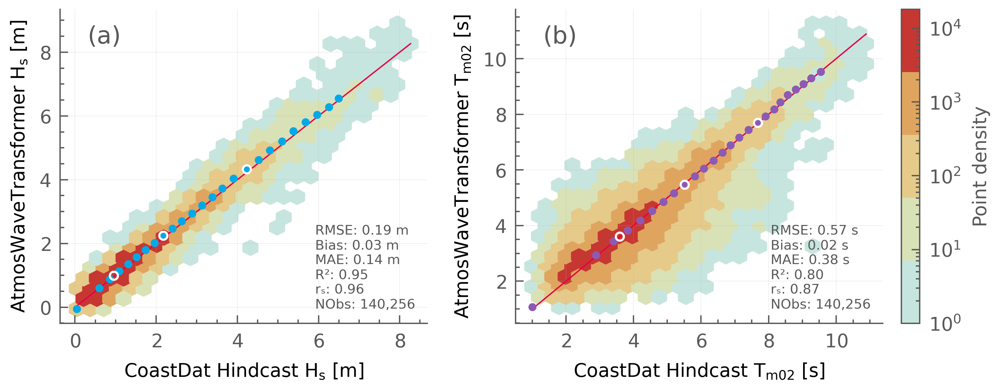

In [65]:
fig, axes, cbar = plot_density_scatter(
    hs_obs=test_wam_df['hs'].values,
    hs_pred=test_pyt_df['hs'].values,
    t0_obs=test_wam_df['t0'].values,
    t0_pred=test_pyt_df['t0'].values
)
plt.tight_layout()

# fig.savefig(f'../results/slides/fig_error-plots.png', dpi=900)

**directional bias calculation**

In [66]:
def angular_difference_deg(pred, obs):
    diff = pred - obs
    # wrap to [-180, 180)
    diff = (diff + 180) % 360 - 180
    return diff

In [67]:
#this is the bias
angular_difference_deg(test_pyt_df['thq'],test_wam_df['thq']).mean()

np.float32(-0.17280789)

In [68]:
#this is MAE:
np.abs(angular_difference_deg(test_pyt_df['thq'], test_wam_df['thq'])).mean()

np.float32(10.042563)

### now, trying to test the same model (with same hperparametes/architectural setup) on living lab locations

In [69]:
test_pyt_NST_df = pd.read_parquet("../results/2026_06_29_wave_data_pyt_NST.parquet", engine="auto")
test_wam_NST_df = pd.read_parquet("../results/2026_06_29_wave_data_wam_NST.parquet", engine="auto")

test_pyt_OFD_df = pd.read_parquet("../results/2026_06_29_wave_data_pyt_OFD.parquet", engine="auto")
test_wam_OFD_df = pd.read_parquet("../results/2026_06_29_wave_data_wam_OFD.parquet", engine="auto")

/tmp/ipykernel_2179147/1017090766.py:7: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


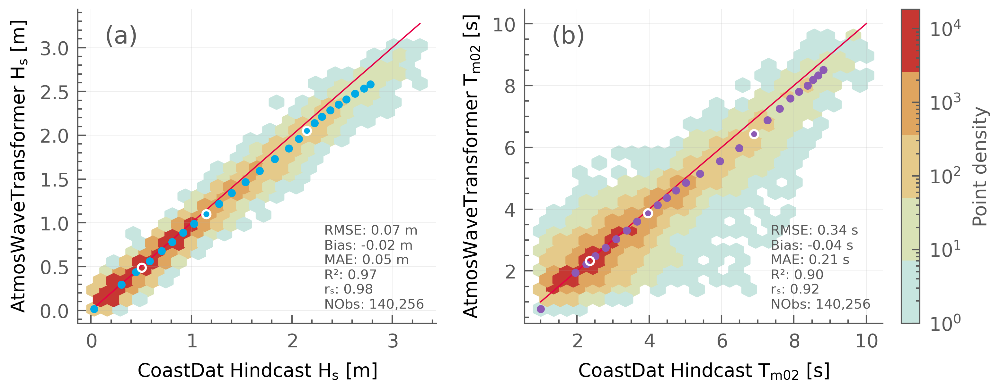

In [70]:
fig, axes, cbar = plot_density_scatter(
    hs_obs=test_wam_OFD_df['hs'].values,
    hs_pred=test_pyt_OFD_df['hs'].values,
    t0_obs=test_wam_OFD_df['t0'].values,
    t0_pred=test_pyt_OFD_df['t0'].values
)
plt.tight_layout()

# fig.savefig(f'../results/slides/fig_error-plots-ofd.png', dpi=900)

/tmp/ipykernel_2179147/3651156340.py:7: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


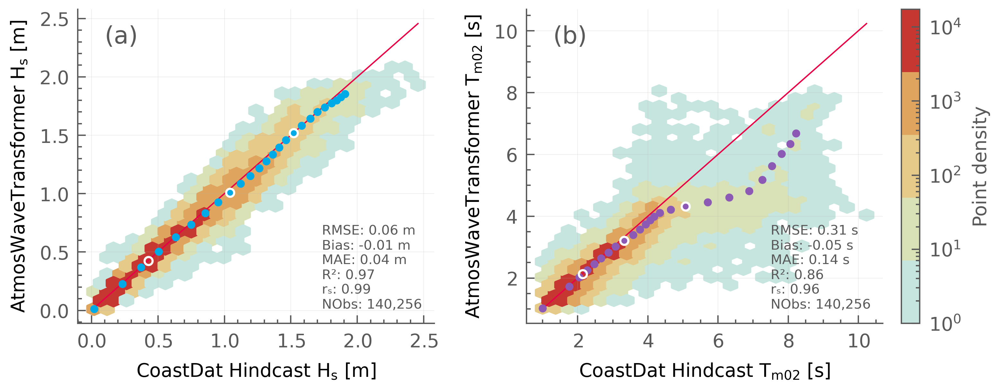

In [71]:
fig, axes, cbar = plot_density_scatter(
    hs_obs=test_wam_NST_df['hs'].values,
    hs_pred=test_pyt_NST_df['hs'].values,
    t0_obs=test_wam_NST_df['t0'].values,
    t0_pred=test_pyt_NST_df['t0'].values
)
plt.tight_layout()

# fig.savefig(f'../results/slides/fig_error-plots-nst.png', dpi=900)

### location map

In [45]:
hereon_cp

[(0.0, 0.5686274509803921, 0.6274509803921569),
 (0.9019607843137255, 0.0, 0.27450980392156865),
 (0.0, 0.6666666666666666, 0.9019607843137255),
 (0.9803921568627451, 0.45098039215686275, 0.3137254901960784),
 (0.9803921568627451, 0.7058823529411765, 0.13725490196078433),
 (0.5490196078431373, 0.35294117647058826, 0.7058823529411765),
 (0.34901960784313724, 0.34901960784313724, 0.34901960784313724),
 (0.7725490196078432, 1.0, 0.9921568627450981),
 (0.5333333333333333, 0.8509803921568627, 0.9019607843137255)]

In [46]:
hereon_cp = utils.hereon_cp

/home/g/g260244/.local/lib/python3.12/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


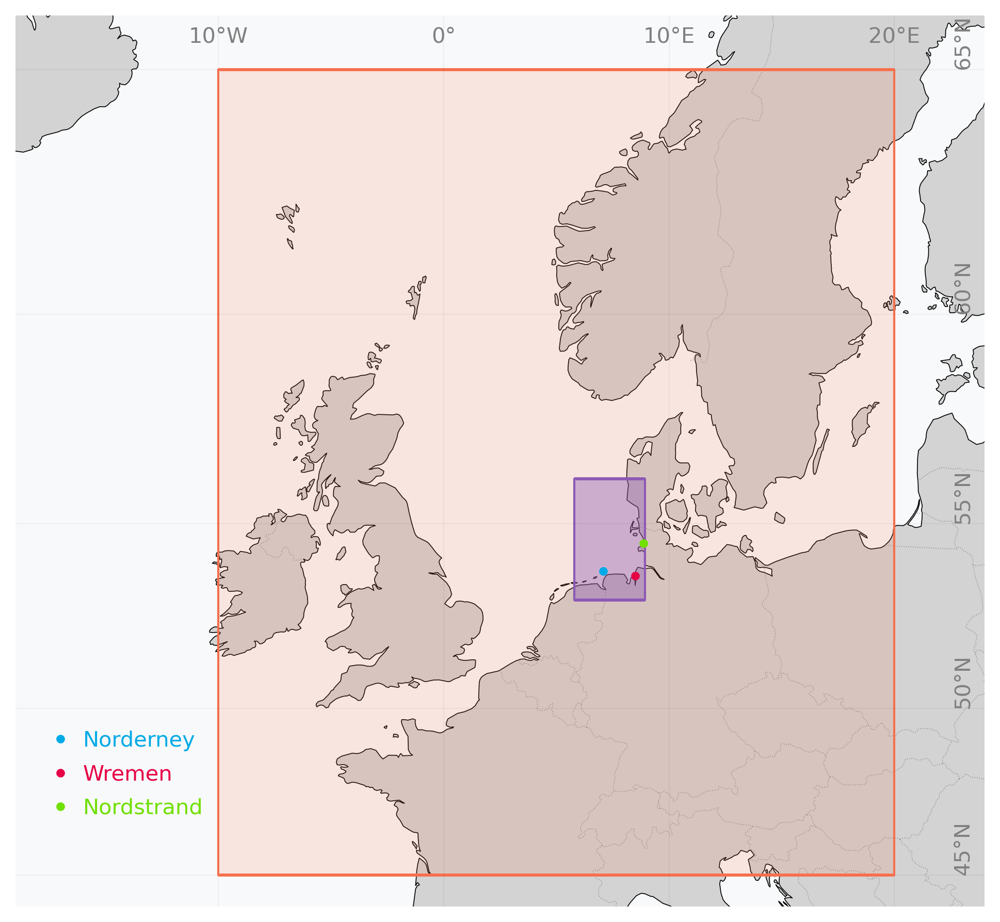

In [72]:
# Define the coordinates
mslp_bounding_box_coords = [-10, 20, 45, 65]  # [lon_min, lon_max, lat_min, lat_max]
wind_bounding_box_coords = [5.8, 8.94, 53.0, 56.13]
point_coord = [7.0903, 53.7675]  # [longitude, latitude]

# Create a figure and axes with a Plate Carree projection
fig = plt.figure(figsize=(3.4, 8), dpi=600)
ax = fig.add_subplot(1, 1, 1, projection=ccrs.Mercator())   
#Mercator(),PlateCarree(), .LambertConformal(central_longitude=5, central_latitude=55)),Mollweide(),Orthographic()

# Set the extent of the map
ax.set_extent([-19, 24, 44, 66], crs=ccrs.PlateCarree())

# Add coastlines
ax.coastlines(resolution='50m', color='black', linewidth=0.2)

# Add country borders
ax.add_feature(cfeature.BORDERS, linewidth=0.2, color='gray', alpha=0.75, linestyle=':', edgecolor='gray')

# Add gridlines with labels
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.01, color='k', alpha=1, linestyle='-')
# Set the gridline intervals to 10 degrees
gl.xlocator = mticker.FixedLocator(range(-180, 181, 10))
gl.ylocator = mticker.FixedLocator(range(-90, 91, 5))

# Show only the top and right labels
gl.top_labels = True
gl.right_labels = True
gl.bottom_labels = False
gl.left_labels = False

# Adjust label padding to move them closer to the map border
gl.xlabel_style = {'size': 5, 'color': 'grey', 'rotation': 0, 'ha': 'center', 'va': 'center'}
gl.ylabel_style = {'size': 5, 'color': 'grey', 'rotation': 90, 'ha': 'center', 'va': 'bottom'}
gl.xpadding = -5  # Negative value moves labels closer
gl.ypadding = -5  # Negative value moves labels closer

# Create the bounding box rectangle
mslp_lon_min, mslp_lon_max, mslp_lat_min, mslp_lat_max = mslp_bounding_box_coords
geom_mslp = sgeom.box(mslp_lon_min, mslp_lat_min, mslp_lon_max, mslp_lat_max)
ax.add_geometries([geom_mslp], ccrs.PlateCarree(),facecolor=mcolors.to_rgba(hereon_cp[3], alpha=0.15),
                  edgecolor =mcolors.to_rgba(hereon_cp[3], alpha=1), linewidth = 0.5,
                 )

wind_lon_min, wind_lon_max, wind_lat_min, wind_lat_max = wind_bounding_box_coords
geom_wind = sgeom.box(wind_lon_min, wind_lat_min, wind_lon_max, wind_lat_max)
ax.add_geometries([geom_wind], ccrs.PlateCarree(),facecolor=mcolors.to_rgba(hereon_cp[5], alpha=0.4),
                  edgecolor =mcolors.to_rgba(hereon_cp[5], alpha=1), linewidth = 0.5
                 )

# Plot the point
ax.plot(point_coord[0], point_coord[1], 'o', color=hereon_cp[2], markersize=1, transform=ccrs.PlateCarree())
# ax.text(point_coord[0] - 4, point_coord[1]+0.23, 'Wave data', color=utils.hereon_cp[2], transform=ccrs.PlateCarree(), fontsize =5)

ax.add_feature(cfeature.LAND, facecolor='lightgrey')  # colour for land
ax.add_feature(cfeature.OCEAN, facecolor='#f8f9fa')  # <- ADD THIS

marker_style = dict(markerfacecolor=hereon_cp[1], linestyle='-', marker='v',
                    markersize=2, markeredgecolor=hereon_cp[1], markeredgewidth = 0.25)
# Plot the 2 living lab locations..., 
ax.plot(8.874584, 54.493331, 'o', color='#70e000', markersize=1, transform=ccrs.PlateCarree())  #**marker_style,
ax.plot(8.507018, 53.647523, 'o', color=hereon_cp[1], markersize=1, transform=ccrs.PlateCarree())

#add a legend
# Plot the 2 living lab locations..., 
ax.plot(-17, 49.125, 'o', color=hereon_cp[2], markersize=1, transform=ccrs.PlateCarree())
ax.text(-16, 48.9, 'Norderney', color=utils.hereon_cp[2], transform=ccrs.PlateCarree(), fontsize =5)
ax.plot(-17, 48.125,'o', color=hereon_cp[1], markersize=1, transform=ccrs.PlateCarree())
ax.text(-16, 47.9, 'Wremen', color=utils.hereon_cp[1], transform=ccrs.PlateCarree(), fontsize =5)
ax.plot(-17, 47.125,'o', color='#70e000', markersize=1, transform=ccrs.PlateCarree())
ax.text(-16, 46.9, 'Nordstrand', color='#70e000', transform=ccrs.PlateCarree(), fontsize =5)
# ax.plot(-17, 47, transform=ccrs.PlateCarree(),**marker_style)
# ax.text(-16, 46.9, 'Living Lab 02', color=utils.hereon_cp[1], transform=ccrs.PlateCarree(), fontsize =5)


ax.spines['geo'].set_linewidth(0)

# fig.savefig(f'../results/slides/fig_location.png', dpi=600)

In [48]:
#check this basemaap? https://www.grida.no/resources/5375

In [49]:
utils.hereon_cp

[(0.0, 0.5686274509803921, 0.6274509803921569),
 (0.9019607843137255, 0.0, 0.27450980392156865),
 (0.0, 0.6666666666666666, 0.9019607843137255),
 (0.9803921568627451, 0.45098039215686275, 0.3137254901960784),
 (0.9803921568627451, 0.7058823529411765, 0.13725490196078433),
 (0.5490196078431373, 0.35294117647058826, 0.7058823529411765),
 (0.34901960784313724, 0.34901960784313724, 0.34901960784313724),
 (0.7725490196078432, 1.0, 0.9921568627450981),
 (0.5333333333333333, 0.8509803921568627, 0.9019607843137255)]

/home/g/g260244/.local/lib/python3.12/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


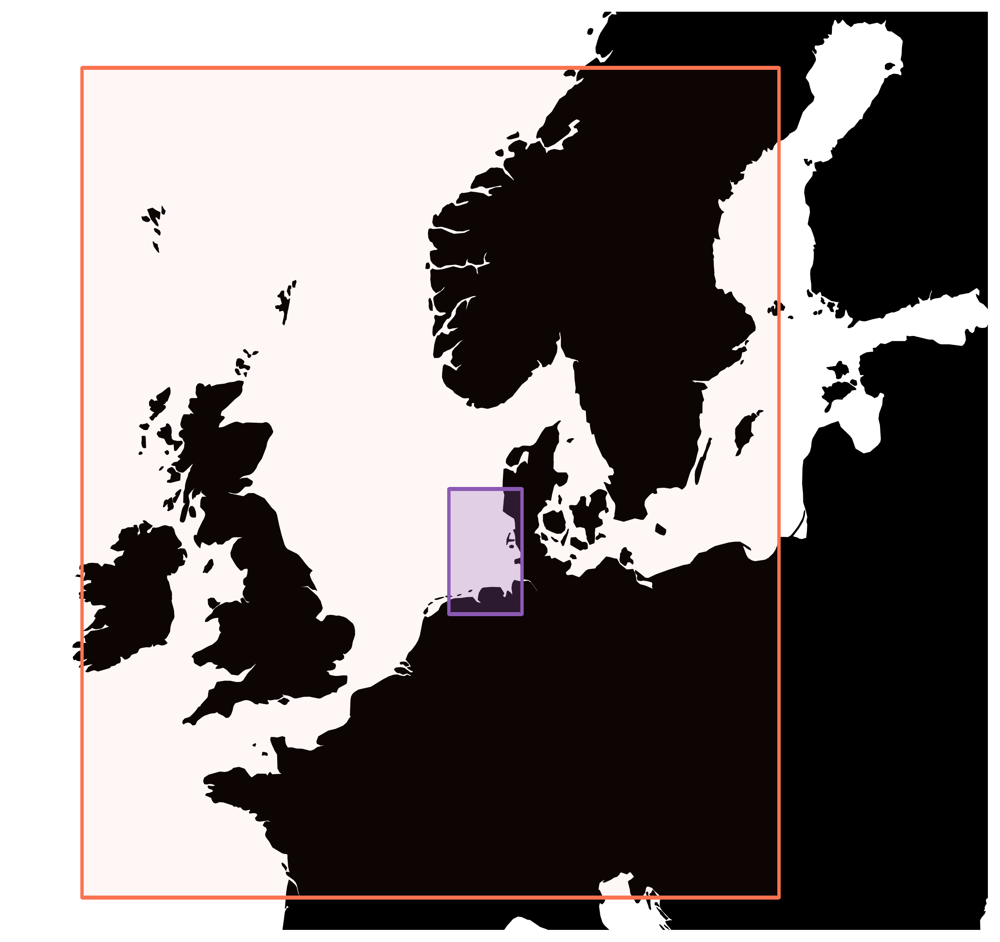

In [50]:
# Define the coordinates
mslp_bounding_box_coords = [-10, 20, 45, 65]  # [lon_min, lon_max, lat_min, lat_max]
wind_bounding_box_coords = [5.8, 8.94, 53.0, 56.13]
point_coord = [7.0903, 53.7675]  # [longitude, latitude]

# Create a figure and axes with a Plate Carree projection
fig = plt.figure(figsize=(4.8, 4), dpi=600)
ax = fig.add_subplot(1, 1, 1, projection=ccrs.Mercator())   
#Mercator(),PlateCarree(), .LambertConformal(central_longitude=5, central_latitude=55)),Mollweide(),Orthographic()

# Set the extent of the map
ax.set_extent([-13, 29, 44, 66], crs=ccrs.PlateCarree())

# Add coastlines
ax.coastlines(resolution='50m', color='black', linewidth=0.2)

# Add country borders
ax.add_feature(cfeature.BORDERS, linewidth=0, color=None, alpha=0, linestyle=':', edgecolor=None)

gl.xlocator = mticker.FixedLocator(range(-180, 181, 10))
gl.ylocator = mticker.FixedLocator(range(-90, 91, 5))

# Show only the top and right labels
gl.top_labels = False
gl.right_labels = False
gl.bottom_labels = False
gl.left_labels = False

# Create the bounding box rectangle--MSLP
mslp_lon_min, mslp_lon_max, mslp_lat_min, mslp_lat_max = mslp_bounding_box_coords
geom_mslp = sgeom.box(mslp_lon_min, mslp_lat_min, mslp_lon_max, mslp_lat_max)
ax.add_geometries([geom_mslp], ccrs.PlateCarree(),facecolor=mcolors.to_rgba(hereon_cp[3], alpha=0.05),
                  edgecolor =mcolors.to_rgba(hereon_cp[3], alpha=1.0), linewidth = 1,
                 )

# Create the bounding box rectangle--wind
wind_lon_min, wind_lon_max, wind_lat_min, wind_lat_max = wind_bounding_box_coords
geom_wind = sgeom.box(wind_lon_min, wind_lat_min, wind_lon_max, wind_lat_max)
ax.add_geometries([geom_wind], ccrs.PlateCarree(),facecolor=mcolors.to_rgba(hereon_cp[5], alpha=0.25),
                  edgecolor =mcolors.to_rgba(hereon_cp[5], alpha=1), linewidth = 1
                 )

ax.add_feature(cfeature.LAND, facecolor='k')  # colour for land
ax.add_feature(cfeature.OCEAN, facecolor='white')  # <- ADD THIS

ax.spines['geo'].set_linewidth(0)

# fig.savefig(f'../results/figures/fig_loc_visual_abs.png', dpi=600)

## bin

In [51]:
#to have Orthographic boxes
def geographic_box(lon_min, lon_max, lat_min, lat_max, n=50):
    # Sample edges
    lons_top = np.linspace(lon_min, lon_max, n)
    lons_bottom = np.linspace(lon_min, lon_max, n)
    lats_left = np.linspace(lat_min, lat_max, n)
    lats_right = np.linspace(lat_min, lat_max, n)

    points = []

    # bottom edge
    for lon in lons_bottom:
        points.append((lon, lat_min))
    # right edge
    for lat in lats_right:
        points.append((lon_max, lat))
    # top edge
    for lon in reversed(lons_top):
        points.append((lon, lat_max))
    # left edge
    for lat in reversed(lats_left):
        points.append((lon_min, lat))

    return sgeom.Polygon(points)

In [52]:
fig.get_figheight()

np.float64(4.0)

/home/g/g260244/.local/lib/python3.12/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


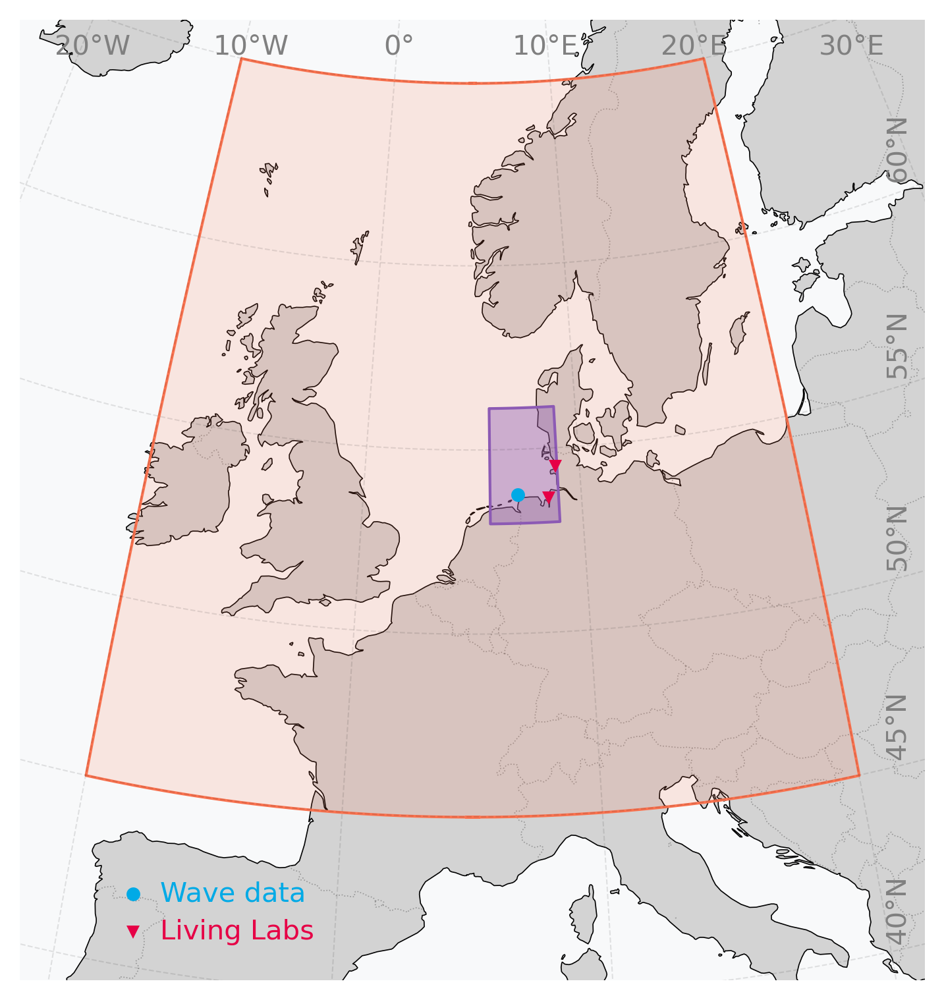

In [53]:
%matplotlib inline
# Define the coordinates
mslp_bounding_box_coords = [-10, 20, 45, 65]  # [lon_min, lon_max, lat_min, lat_max]
wind_bounding_box_coords = [5.8, 8.94, 53.0, 56.13]
point_coord = [7.0903, 53.7675]  # [longitude, latitude]

marker_style_tri = dict(linestyle='-', marker='v', markerfacecolor=hereon_cp[1],
                    markersize=2.5, markeredgecolor=hereon_cp[1], markeredgewidth = 0)

marker_style_cir = dict(linestyle='none', marker='o', markerfacecolor=hereon_cp[2], 
                    markersize=2.5, markeredgecolor=hereon_cp[2], markeredgewidth = 0)

# Create a figure and axes with a Plate Carree projection
fig = plt.figure(dpi=600)
fig.set_size_inches(fig.get_figheight(),4.2)
ax = fig.add_subplot(1, 1, 1, projection=ccrs.Orthographic(central_longitude=5, central_latitude=55))   
#Mercator(),PlateCarree(), .LambertConformal(central_longitude=5, central_latitude=55)),Mollweide(),Orthographic()

# Set the extent of the map
ax.set_extent([-11, 21, 39, 66], crs=ccrs.PlateCarree())

# Add coastlines
ax.coastlines(resolution='50m', color='black', linewidth=0.2)
# Add country borders
ax.add_feature(cfeature.BORDERS, linewidth=0.2, color='gray', alpha=0.75, linestyle=':', edgecolor='gray')

# Add gridlines with labels
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, linewidth=0.25, color='k', alpha=.1, linestyle='--')

# Set the gridline intervals to 10 degrees
gl.xlocator = mticker.FixedLocator(range(-180, 181, 10))
gl.ylocator = mticker.FixedLocator(range(-90, 91, 5))

# Show only the top and right labels
gl.top_labels = True
gl.right_labels = True
gl.bottom_labels = False
gl.left_labels = False

# Adjust label padding to move them closer to the map border
gl.xlabel_style = {'size': 5, 'color': 'grey', 'rotation': 0, 'ha': 'center', 'va': 'center'}
gl.ylabel_style = {'size': 5, 'color': 'grey', 'rotation': 90, 'ha': 'center', 'va': 'bottom'}
gl.xpadding = -5  # Negative value moves labels closer
gl.ypadding = -5  # Negative value moves labels closer


ax.add_feature(cfeature.LAND, facecolor='lightgrey')  # colour for land
ax.add_feature(cfeature.OCEAN, facecolor='#f8f9fa')  # <- ADD THIS

# Create the bounding box rectangle
mslp_lon_min, mslp_lon_max, mslp_lat_min, mslp_lat_max = mslp_bounding_box_coords
geom_mslp = geographic_box(mslp_lon_min, mslp_lon_max, mslp_lat_min, mslp_lat_max)
ax.add_geometries([geom_mslp], ccrs.PlateCarree(),facecolor=mcolors.to_rgba(hereon_cp[3], alpha=0.15),
                  edgecolor =mcolors.to_rgba(hereon_cp[3], alpha=1), linewidth = 0.5,
                 )

wind_lon_min, wind_lon_max, wind_lat_min, wind_lat_max = wind_bounding_box_coords
geom_wind = geographic_box(wind_lon_min, wind_lon_max, wind_lat_min, wind_lat_max)
ax.add_geometries([geom_wind], ccrs.PlateCarree(),facecolor=mcolors.to_rgba(hereon_cp[5], alpha=0.4),
                  edgecolor =mcolors.to_rgba(hereon_cp[5], alpha=1), linewidth = 0.5
                 )

# Plot the point--wave data
ax.plot(point_coord[0], point_coord[1], **marker_style_cir, transform=ccrs.PlateCarree())
# ax.text(point_coord[0] - 4, point_coord[1]+0.23, 'Wave data', color=utils.hereon_cp[2], transform=ccrs.PlateCarree(), fontsize =5)

# Plot the 2 living lab locations..., 
ax.plot(8.874584, 54.493331,**marker_style_tri, transform=ccrs.PlateCarree())
ax.plot(8.507018, 53.647523,**marker_style_tri, transform=ccrs.PlateCarree())

#add a legend
legend_x,legend_y1, legend_y2 = 0.125,0.09,0.05

# Wave data
ax.plot(legend_x, legend_y1, **marker_style_cir,transform=ax.transAxes)
ax.text(legend_x + 0.03, legend_y1, 'Wave data', fontsize=5,color=hereon_cp[2], transform=ax.transAxes, va='center')

# Living Labs
ax.plot(legend_x, legend_y2, **marker_style_tri, transform=ax.transAxes)
ax.text(legend_x + 0.03, legend_y2, 'Living Labs', fontsize=5, color=hereon_cp[1], transform=ax.transAxes, va='center')

ax.spines['geo'].set_linewidth(0)

# fig.savefig(f'../results/figures/fig_location.png', dpi=600)

In [54]:
test_pyt_df

,hs,t0,thq
2008-01-01 01:00:00,0.547419,4.581403,172.619583
2008-01-01 02:00:00,0.468353,4.061697,175.076752
2008-01-01 03:00:00,0.413091,3.543553,177.191864
2008-01-01 04:00:00,0.380323,3.113977,176.922211
2008-01-01 05:00:00,0.334470,2.746624,174.605270
...,...,...,...
2023-12-31 19:00:00,0.983358,2.744562,23.783211
2023-12-31 20:00:00,1.063076,2.825773,24.594294
2023-12-31 21:00:00,1.173594,2.931490,27.033688
2023-12-31 22:00:00,1.272543,3.097497,36.755718


In [55]:
test_wam_df

,hs,t0,thq
2008-01-01 01:00:00,0.879712,5.258317,161.311691
2008-01-01 02:00:00,0.850048,5.212195,161.318787
2008-01-01 03:00:00,0.822923,5.005302,161.167847
2008-01-01 04:00:00,0.799246,4.693956,160.847885
2008-01-01 05:00:00,0.777400,4.456815,160.518127
...,...,...,...
2023-12-31 19:00:00,1.066648,2.810201,23.762955
2023-12-31 20:00:00,1.115698,2.906793,21.619234
2023-12-31 21:00:00,1.191125,2.974620,26.958761
2023-12-31 22:00:00,1.316044,3.116665,36.148533


### nik's comments on quartiles based on hs for t0 as well

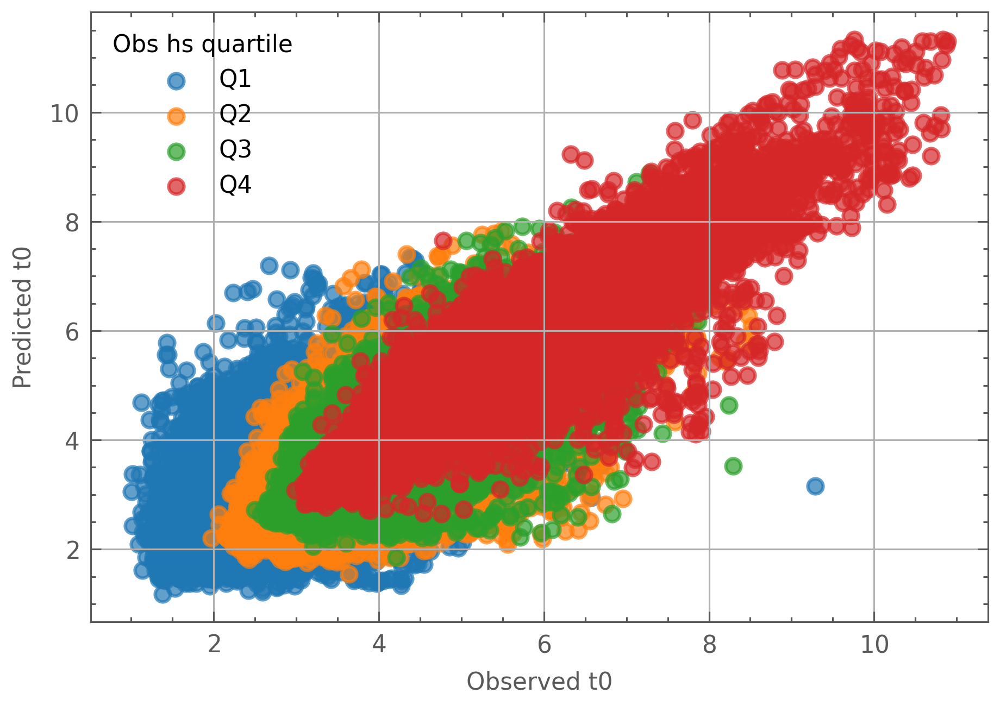

In [56]:
# quartiles of observed hs
q = test_wam_df['hs'].quantile([0.25, 0.5, 0.75])

# assign quartile labels based on obs hs
quart = pd.cut(
    test_wam_df['hs'],
    bins=[-float('inf'), q[0.25], q[0.5], q[0.75], float('inf')],
    labels=['Q1', 'Q2', 'Q3', 'Q4']
)

colors = {'Q1':'tab:blue', 'Q2':'tab:orange', 'Q3':'tab:green', 'Q4':'tab:red'}

fig = plt.figure(figsize=(4.2, 3), dpi=450)
for qlab, col in colors.items():
    m = quart == qlab
    plt.scatter(test_wam_df.loc[m, 't0'], test_pyt_df.loc[m, 't0'],
                s=20, alpha=0.7, label=qlab, color=col)

plt.xlabel('Observed t0')
plt.ylabel('Predicted t0')
plt.legend(title='Obs hs quartile')
plt.grid(True)
plt.tight_layout()
plt.show()

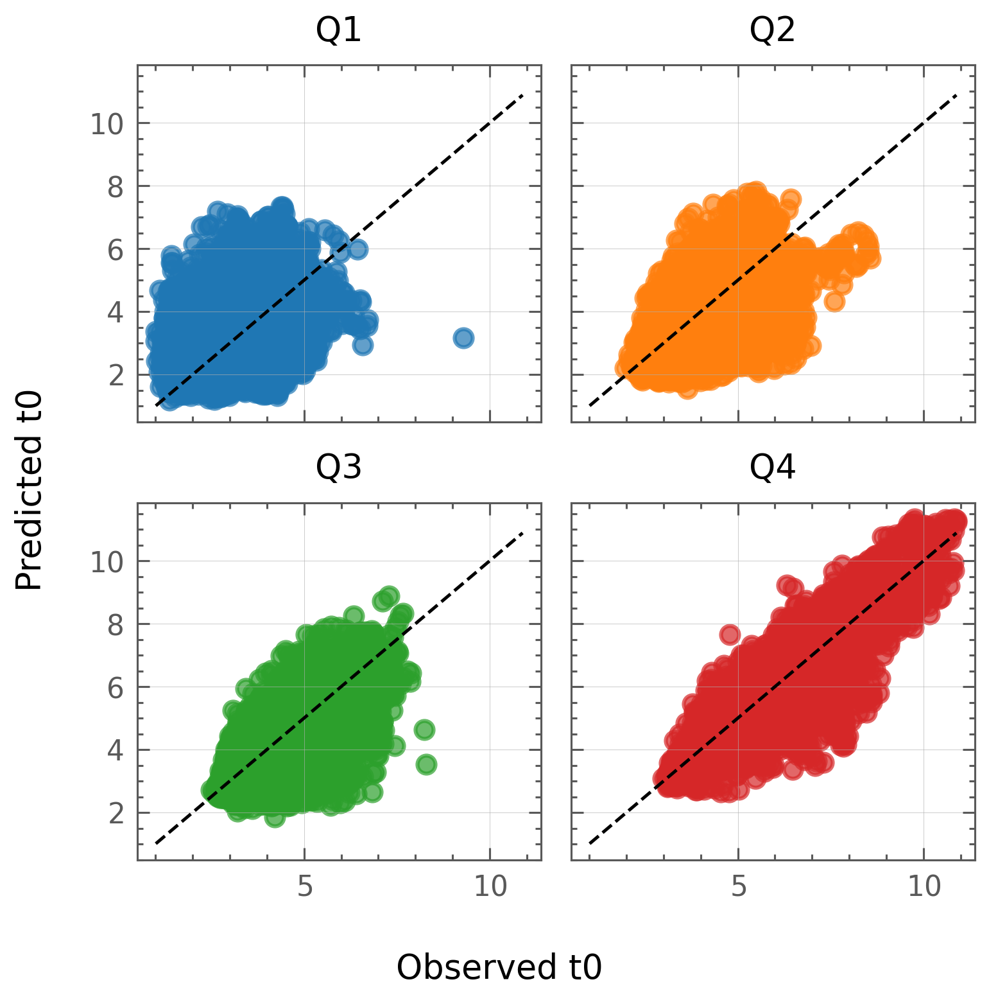

In [57]:
fig, axes = plt.subplots(2, 2, figsize=(3.5, 3.5), dpi=450,
                         sharex=True, sharey=True)
axes = axes.ravel()

for i, qlab in enumerate(['Q1', 'Q2', 'Q3', 'Q4']):
    m = quart == qlab
    axes[i].scatter(
        test_wam_df.loc[m, 't0'],
        test_pyt_df.loc[m, 't0'],
        s=20, alpha=0.7, color=colors[qlab]
    )
    axes[i].set_title(qlab)
    axes[i].grid(linewidth = 0.1)
    xmin = test_wam_df['t0'].min()
    xmax = test_wam_df['t0'].max()
    axes[i].plot([xmin, xmax], [xmin, xmax], 'k--', lw=0.8)


fig.supxlabel('Observed t0')
fig.supylabel('Predicted t0')

plt.tight_layout()
plt.show()

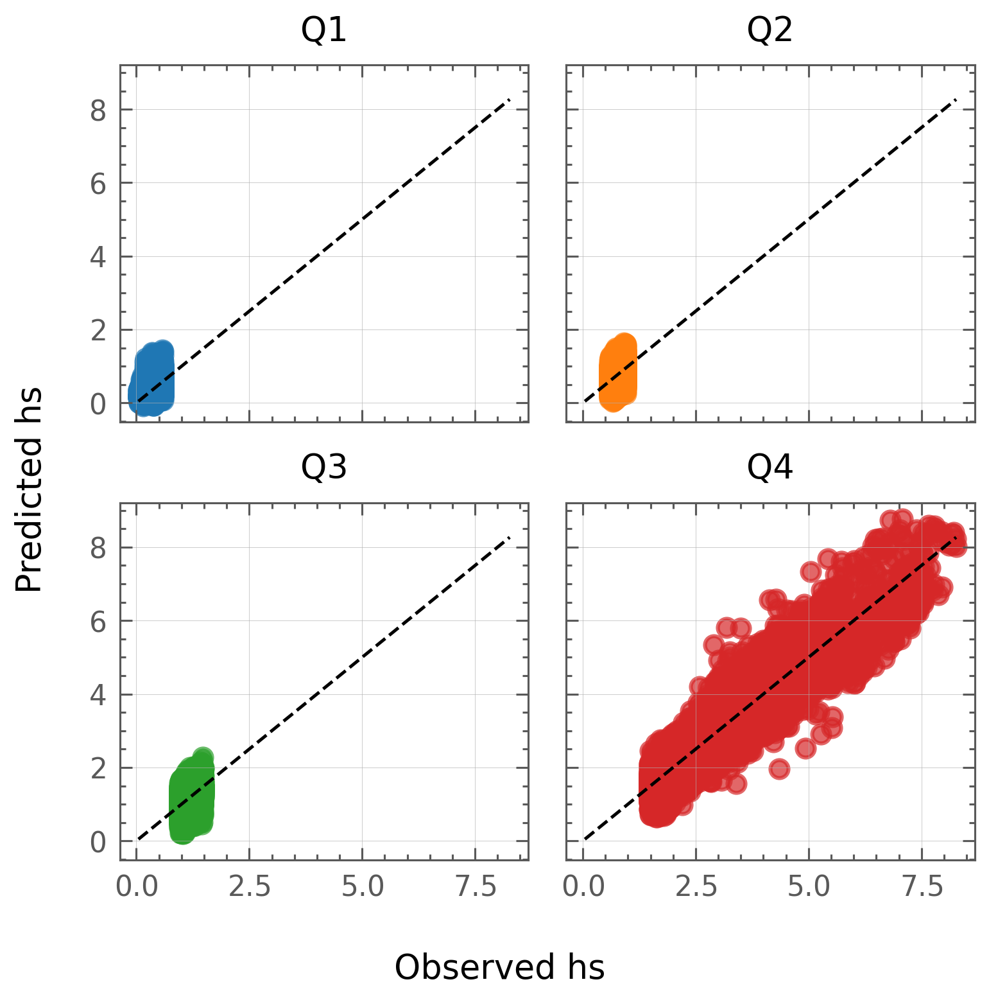

In [58]:
fig, axes = plt.subplots(2, 2, figsize=(3.5, 3.5), dpi=450,
                         sharex=True, sharey=True)
axes = axes.ravel()

for i, qlab in enumerate(['Q1', 'Q2', 'Q3', 'Q4']):
    m = quart == qlab
    axes[i].scatter(
        test_wam_df.loc[m, 'hs'],
        test_pyt_df.loc[m, 'hs'],
        s=20, alpha=0.7, color=colors[qlab]
    )
    axes[i].set_title(qlab)
    axes[i].grid(linewidth = 0.1)
    xmin = test_wam_df['hs'].min()
    xmax = test_wam_df['hs'].max()
    axes[i].plot([xmin, xmax], [xmin, xmax], 'k--', lw=0.8)


fig.supxlabel('Observed hs')
fig.supylabel('Predicted hs')

plt.tight_layout()
plt.show()